In [7]:
import pandas as pd

df = pd.read_csv("netflix_titles.csv")
print(df.shape)
print(df.isnull().sum())

(8807, 12)
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [8]:
# 1. Remove repeated rows
df = df.drop_duplicates()

# 2. Fill empty text columns with "Unknown"
for col in ["director", "cast", "country"]:
    df[col] = df[col].fillna("Unknown")

# 3. Drop the few rows missing important fields
df = df.dropna(subset=["date_added", "rating", "duration"])

# 4. Fix the date column (it is text right now)
df["date_added"] = pd.to_datetime(df["date_added"].str.strip())
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month

# 5. Split duration like "90 min" or "2 Seasons" into number and unit
df["duration_value"] = df["duration"].str.split(" ").str[0].astype(int)
df["duration_unit"] = df["duration"].str.split(" ").str[1]

print(df.shape)
print(df.isnull().sum())

(8790, 16)
show_id           0
type              0
title             0
director          0
cast              0
country           0
date_added        0
release_year      0
rating            0
duration          0
listed_in         0
description       0
year_added        0
month_added       0
duration_value    0
duration_unit     0
dtype: int64


In [11]:
import sqlite3

conn = sqlite3.connect("netflix.db")
df.to_sql("titles", conn, if_exists="replace", index=False)
print("Saved to database!")

Saved to database!


In [13]:
def run(query):
    return pd.read_sql(query, conn)

# Question 1: How many Movies vs TV Shows?
print(run("SELECT type, COUNT(*) AS total FROM titles GROUP BY type"))



      type  total
0    Movie   6126
1  TV Show   2664


In [14]:
print(run("""
    SELECT year_added, COUNT(*) AS total
    FROM titles
    GROUP BY year_added
    ORDER BY year_added
"""))

    year_added  total
0         2008      2
1         2009      2
2         2010      1
3         2011     13
4         2012      3
5         2013     11
6         2014     24
7         2015     82
8         2016    426
9         2017   1185
10        2018   1648
11        2019   2016
12        2020   1879
13        2021   1498


In [15]:
print(run("""
    SELECT country, COUNT(*) AS total
    FROM titles
    WHERE country != 'Unknown'
    GROUP BY country
    ORDER BY total DESC
    LIMIT 10
"""))

          country  total
0   United States   2809
1           India    972
2  United Kingdom    418
3           Japan    243
4     South Korea    199
5          Canada    181
6           Spain    145
7          France    124
8          Mexico    110
9           Egypt    106


In [16]:
print(run("""
    SELECT year_added, COUNT(*) AS total,
           RANK() OVER (ORDER BY COUNT(*) DESC) AS year_rank
    FROM titles
    GROUP BY year_added
"""))

    year_added  total  year_rank
0         2019   2016          1
1         2020   1879          2
2         2018   1648          3
3         2021   1498          4
4         2017   1185          5
5         2016    426          6
6         2015     82          7
7         2014     24          8
8         2011     13          9
9         2013     11         10
10        2012      3         11
11        2009      2         12
12        2008      2         12
13        2010      1         14


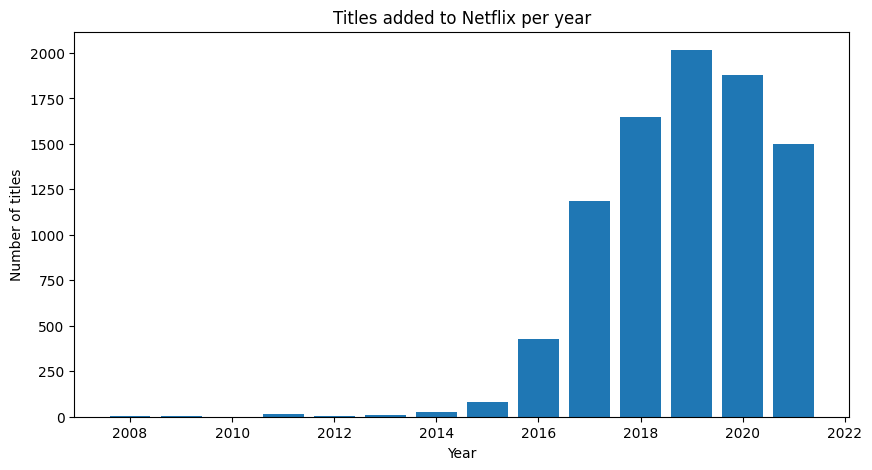

In [17]:
import matplotlib.pyplot as plt

data = run("SELECT year_added, COUNT(*) AS total FROM titles GROUP BY year_added ORDER BY year_added")

plt.figure(figsize=(10, 5))
plt.bar(data["year_added"], data["total"])
plt.title("Titles added to Netflix per year")
plt.xlabel("Year")
plt.ylabel("Number of titles")
plt.savefig("titles_per_year.png")
plt.show()